# 7.2 · 订单管理：订单类型与智能下单

> 组合优化给出"目标权重"，但**怎么把它变成真实成交**是另一门学问——大单一次性下会造成巨大冲击成本。
> 订单管理（OMS）负责订单类型、生命周期，以及**算法交易（智能下单/拆单）**，以更低成本、更接近合理价格完成交易。
> 这是交易执行（execution）环节的核心，也是量化交易岗位的重要内容。

## 一、订单类型

| 类型 | 说明 | 特点 |
|---|---|---|
| **市价单 Market** | 立即按市场价成交 | 保证成交，价格不确定 |
| **限价单 Limit** | 限定价格或更优成交 | 价格可控，可能不成交 |
| **止损单 Stop** | 触及止损价触发 | 控制亏损 |
| **止盈单** | 到目标价触发 | 锁定利润 |
| **FAK/FOK** | 立即成交剩余撤销/全部成交否则撤销 | 常见于期货 |
| **冰山单** | 只显示部分数量 | 隐藏大单意图 |

> 选股多用限价单（控制价格），紧急调整用市价单（保证成交）。

## 二、订单生命周期

NEW（新建）→ SUBMITTED（已报）→ PARTIAL（部分成交）→ FILLED（全部成交）；
中途可能 CANCELLED（撤单）、REJECTED（拒单）。

订单管理要跟踪每张订单的状态、成交数量、均价，并处理拒单、超时、部分成交。

## 三、为什么要拆单 / 算法交易

- 一次性下大单 → 吃掉多档盘口、暴露意图、冲击成本高；
- 把大单**拆成小单、分散到一段时间**，每笔参与率低 → 冲击小；
- 算法交易（execution algo）自动决定"何时、下多少"，目标是最小化执行成本。

常见算法：
- **TWAP（时间加权）**：均匀拆到每个时间片；
- **VWAP（成交量加权）**：按历史成交量分布拆（量大时多下）；
- **POV（参与率）**：跟随市场实时成交量，维持固定参与率；
- **IS（执行落差）**：平衡冲击与价格风险，追求总成本最小。

代码在 live_lab.orders。

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab.orders import twap_schedule, vwap_schedule, pov_schedule
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
total = 100000
profile = np.array([12,10,8,7,6,7,8,9,10,12,11,10,9,8,7,8,10,12])
tw = twap_schedule(total, 18)
vw = vwap_schedule(total, profile)
mkt_vol = np.array([50000,60000,45000,55000,40000,50000,60000,70000,
                    65000,55000,50000,60000,70000,65000,55000,60000,
                    55000,60000])
pov = pov_schedule(mkt_vol, 0.1, total)
print('TWAP 合计 %.0f；VWAP 合计 %.0f；POV 合计 %.0f（%d片）' %
      (tw.sum(), vw.sum(), pov.sum(), len(pov)))

TWAP 合计 100000；VWAP 合计 100000；POV 合计 100000（18片）


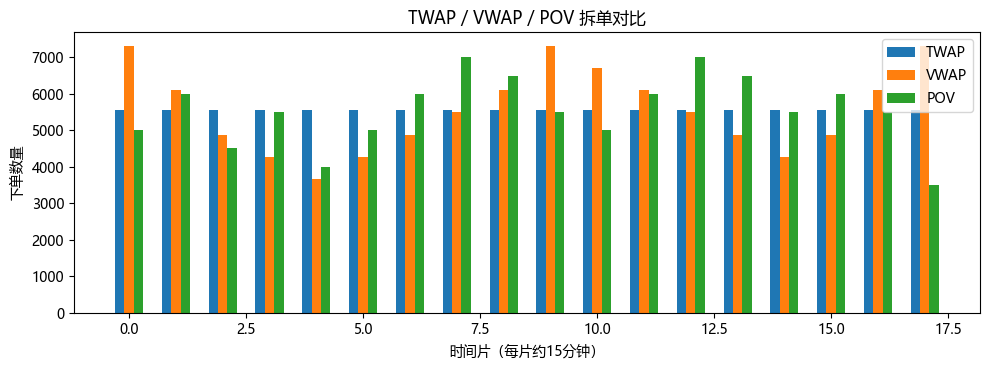

In [2]:
# 拆单对比
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(18)
ax.bar(x-0.2, tw, width=0.2, label='TWAP')
ax.bar(x, vw, width=0.2, label='VWAP')
ax.bar(x+0.2, np.r_[pov, np.zeros(18-len(pov))], width=0.2, label='POV')
ax.set_xlabel('时间片（每片约15分钟）'); ax.set_ylabel('下单数量')
ax.set_title('TWAP / VWAP / POV 拆单对比'); ax.legend()
plt.tight_layout(); plt.show()

## 四、各算法的适用场景

- **TWAP**：简单、可预测，适合成交量分布均匀、规模不大的单；
- **VWAP**：贴合市场成交节奏，最常用，适合不急于成交、希望"跑赢市场均价"的单；
- **POV**：实时跟随市场，市场活跃时多下，适合希望与市场同步参与；
- **IS**：当交易有时间压力且怕价格漂移时，平衡冲击与时机风险。

> 算法越好，越能降低执行成本，但都无法完全消除成本；执行质量要用量化指标评估（如相对 VWAP/到达价的偏离）。

## 五、小结与面试要点

- 订单类型：市价、限价、止损、FAK/FOK、冰山；生命周期需全程跟踪。
- 拆单/算法交易降低冲击：TWAP 均匀、VWAP 跟随量分布、POV 跟随参与率、IS 平衡成本。
- 不同算法适用不同场景；执行质量要量化评估。

**面试高频：**
- 市价单和限价单的区别？（答：市价保证成交价格不定，限价价格可控可能不成交）
- 什么是 TWAP / VWAP？（答：按时间均匀/按成交量分布拆单）
- 为什么要算法交易？（答：拆单降低参与率和冲击成本，隐藏交易意图）
- 怎么衡量执行好坏？（答：相对 VWAP、到达价、执行落差的偏离）

## 动手练习
1. 用真实/模拟的日内成交量分布，生成 VWAP 拆单；
2. 对比一次性下单 vs TWAP 的估算冲击成本；
3. 思考：如果市场快速上涨，POV 算法可能遇到什么问题。

---
下一节 **7.3 交易接口与模拟盘：券商 API、CTP、对接流程**。